# Bulk ATAC-seq part 3: differential accessibility with DiffBind and DESeq2

**Case study: How does chromatin accessibility in the liver change in a mouse model of diabetes and high-fat diet?**

Jeong BK, Choi WI, Choi W, et al. *A male mouse model for metabolic dysfunction-associated steatotic liver disease and hepatocellular carcinoma.* Nature Communications (2024) 15:6506. https://doi.org/10.1038/s41467-024-50660-y

**Research questions:**

1. How good are the ATAC-seq libraries, and how does their quality shape the results?
2. Which regions change accessibility in the livers of STZ + HFD mice, compared with control mice?
3. Which genes lie near these regions?

This notebook answers questions 2 and 3, compares our results with the paper, and ends with a conclusion on all three questions.

## Introduction

In [part 2](part_2_consensus_peaks_macs_diff.ipynb) we built a consensus peak set, counted fragments per sample, and saw that MACS3 `bdgdiff` cannot separate treatment effects from mouse-to-mouse variation. Here we use statistical methods that **model the variation between replicates**.

Both methods treat the fragment counts like RNA-seq read counts: for each region, the counts of the 12 samples are modelled with a **negative binomial** distribution, whose variance (the *dispersion*) is estimated from the replicates and shared across regions with a similar mean. A region is called differentially accessible if the difference between groups is large compared with this variance, with a false discovery rate (FDR) across all regions tested.

- [**DESeq2**](https://bioconductor.org/packages/DESeq2) (Love et al., 2014) is a general method for count data (RNA-seq, ATAC-seq, ChIP-seq, ...). You provide a count matrix and a design.
- [**DiffBind**](https://bioconductor.org/packages/DiffBind) (Ross-Innes et al., 2012; Stark & Brown) wraps the whole peak-based workflow: it reads peak files and BAM files, builds a consensus, counts, normalises, and runs DESeq2 or edgeR for you.

Plan of this notebook:

1. **DiffBind**: from peak and BAM files to differentially accessible regions (DARs), and the effect of normalisation;
2. **DESeq2** on our own count matrix from part 2, with a simple and a **factorial design** (STZ × diet);
3. comparing DiffBind, DESeq2 and MACS3 `bdgdiff`;
4. annotating DARs to genes with ChIPseeker;
5. saving the results, and a comparison with the paper.

This notebook uses the **R** kernel. As before, all data are restricted to chr19.

## Step 0: Setup

This notebook uses R, with DiffBind, DESeq2, apeglm, ChIPseeker, the mm10 annotation packages and UpSetR. They are in one mamba environment, described in `envs/atac-r.yml`. Create it once and register it as a Jupyter kernel, in a terminal (not in this notebook), from the folder of this notebook:

```
mamba env create -f envs/atac-r.yml
mamba activate atac-r
R -e 'IRkernel::installspec(name = "atac-r", displayname = "R (atac-r)")'
jupyter kernelspec list   # the kernel atac-r should be listed
```

Then (re)start Jupyter and select the kernel "R (atac-r)". Input data are in the folder `data` next to this notebook, our results go to `data/results/part_3`.

In [1]:
suppressPackageStartupMessages({
    library(DiffBind)
    library(DESeq2)
    library(apeglm)
    library(GenomicRanges)
    library(ChIPseeker)
    library(TxDb.Mmusculus.UCSC.mm10.knownGene)
    library(org.Mm.eg.db)
    library(ggplot2)
    library(pheatmap)
    library(UpSetR)
})
options(repr.plot.width = 7, repr.plot.height = 5)

# The folder of this notebook (the kernel starts there). Kept when you run this cell again after setwd below.
if (!exists("here")) here <- getwd()

# Input data, in the folder data next to this notebook
bulk <- file.path(here, "data")

# Your own results
out <- file.path(bulk, "results", "part_3")
dir.create(out, recursive = TRUE, showWarnings = FALSE)
setwd(out)

# Results of part 2 (yours if you ran it, otherwise the pre-generated ones)
nb02 <- file.path(bulk, "results", "part_2")
if (!file.exists(file.path(nb02, "counts_matrix.tsv"))) nb02 <- file.path(bulk, "nb02_generated")
cat("part 2 results:", sub(paste0(here, "/"), "", nb02, fixed = TRUE), "\n")

part 2 results: data/nb02_generated 


The sample sheet describes the design. We turn the experimental factors into R factors and choose the **reference level** of each one (no STZ, standard chow): fold changes are always expressed relative to the reference.

In [2]:
samples <- read.delim(file.path(bulk, "samplesheet.tsv"))
# the first level of each factor is the reference
samples$stz   <- factor(samples$stz, levels = c("no", "yes"))
samples$diet  <- factor(samples$diet, levels = c("SCD", "HFD"))
samples$group <- factor(samples$group, levels = c("SCD", "STZ_SCD", "HFD", "STZ_HFD"))
rownames(samples) <- samples$sample
samples

,sample,run,gsm,stz,diet,group,replicate
,<chr>,<chr>,<chr>,<fct>,<fct>,<fct>,<int>
SCD_1,SCD_1,SRR26515793,GSM7864924,no,SCD,SCD,1
SCD_2,SCD_2,SRR26515791,GSM7864925,no,SCD,SCD,2
SCD_3,SCD_3,SRR26515790,GSM7864926,no,SCD,SCD,3
STZ_SCD_1,STZ_SCD_1,SRR26515789,GSM7864927,yes,SCD,STZ_SCD,1
STZ_SCD_2,STZ_SCD_2,SRR26515792,GSM7864928,yes,SCD,STZ_SCD,2
STZ_SCD_3,STZ_SCD_3,SRR26515788,GSM7864929,yes,SCD,STZ_SCD,3
HFD_1,HFD_1,SRR26515787,GSM7864930,no,HFD,HFD,1
HFD_2,HFD_2,SRR26515786,GSM7864931,no,HFD,HFD,2
HFD_3,HFD_3,SRR26515785,GSM7864932,no,HFD,HFD,3


## Step 1: DiffBind

### 1a. The DiffBind sample sheet

DiffBind starts from a table with one row per sample: metadata columns (`SampleID`, `Tissue`, `Factor`, `Condition`, `Treatment`, `Replicate`), the BAM file with the reads (`bamReads`), and the peak file (`Peaks`, with `PeakCaller` telling DiffBind the format). We use the chr19 BAM files and the per-sample MACS3 peaks from part 2.

In [3]:
sample_sheet <- data.frame(
    SampleID   = samples$sample,
    Tissue     = "liver",
    Factor     = samples$stz,
    Condition  = samples$group,
    Treatment  = samples$diet,
    Replicate  = samples$replicate,
    bamReads   = file.path(bulk, "data_generated", samples$sample, paste0(samples$sample, ".filtered.chr19.bam")),
    Peaks      = file.path(nb02, "peaks", paste0(samples$sample, "_peaks.narrowPeak")),
    PeakCaller = "narrow"
)
# stop with an error if a file is missing; dba() reads the peak files and merges them
stopifnot(all(file.exists(sample_sheet$bamReads)), all(file.exists(sample_sheet$Peaks)))
atac <- dba(sampleSheet = sample_sheet)
atac

SCD_1 liver no SCD SCD 1 narrow

SCD_2 liver no SCD SCD 2 narrow

SCD_3 liver no SCD SCD 3 narrow

STZ_SCD_1 liver yes STZ_SCD SCD 1 narrow

STZ_SCD_2 liver yes STZ_SCD SCD 2 narrow

STZ_SCD_3 liver yes STZ_SCD SCD 3 narrow

HFD_1 liver no HFD HFD 1 narrow

HFD_2 liver no HFD HFD 2 narrow

HFD_3 liver no HFD HFD 3 narrow

STZ_HFD_1 liver yes STZ_HFD HFD 1 narrow

STZ_HFD_2 liver yes STZ_HFD HFD 2 narrow

STZ_HFD_3 liver yes STZ_HFD HFD 3 narrow



12 Samples, 659 sites in matrix (1178 total):
          ID Tissue Factor Condition Treatment Replicate Intervals
1      SCD_1  liver     no       SCD       SCD         1       478
2      SCD_2  liver     no       SCD       SCD         2       438
3      SCD_3  liver     no       SCD       SCD         3       900
4  STZ_SCD_1  liver    yes   STZ_SCD       SCD         1       389
5  STZ_SCD_2  liver    yes   STZ_SCD       SCD         2       465
6  STZ_SCD_3  liver    yes   STZ_SCD       SCD         3       389
7      HFD_1  liver     no       HFD       HFD         1       356
8      HFD_2  liver     no       HFD       HFD         2       384
9      HFD_3  liver     no       HFD       HFD         3       368
10 STZ_HFD_1  liver    yes   STZ_HFD       HFD         1       126
11 STZ_HFD_2  liver    yes   STZ_HFD       HFD         2       272
12 STZ_HFD_3  liver    yes   STZ_HFD       HFD         3       389

The `Intervals` column is the number of peaks per sample. DiffBind has already merged all peaks into a consensus. A first look at the data: the correlation between samples based on **which peaks they share** (occupancy), before counting any reads:

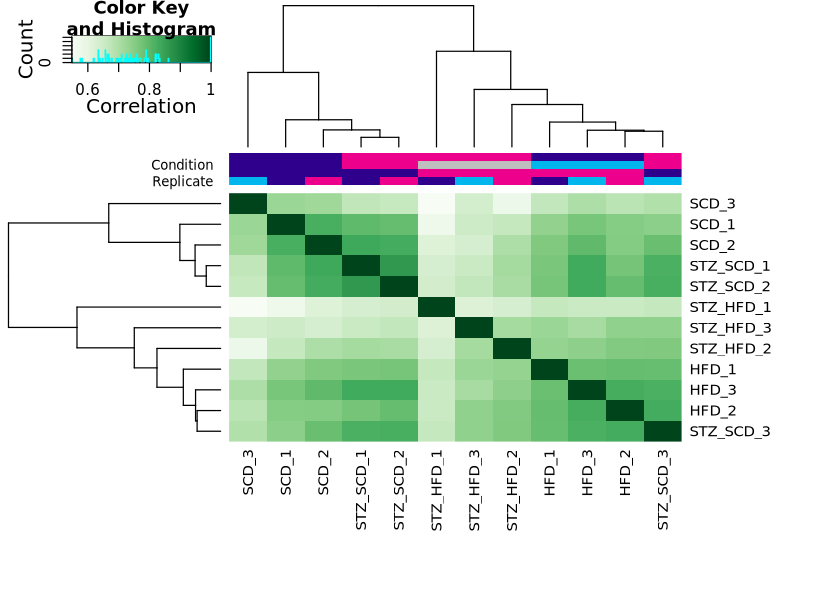

In [4]:
plot(atac)

### 1b. Counting

`dba.count` builds the consensus peak set and counts the fragments of every sample in it. The options follow what we did by hand in part 2:

- `minOverlap = 2`: keep regions that are peaks in at least 2 samples (the default);
- `summits = 250`: re-centre each consensus region on its summit and make it 2 × 250 + 1 = 501 bp wide, like our fixed-width peaks;
- the reads are paired, so we tell DiffBind to count fragments (`singleEnd = FALSE`).

Counting reads all BAM files and takes a minute or two.

In [5]:
atac$config$singleEnd <- FALSE
atac$config$cores <- 4
# bUseSummarizeOverlaps: count with Bioconductor's summarizeOverlaps, which handles read pairs as fragments
atac <- dba.count(atac, minOverlap = 2, summits = 250, bUseSummarizeOverlaps = TRUE)
atac

Computing summits...

Re-centering peaks...

Reads will be counted as Paired-end.



12 Samples, 658 sites in matrix:
          ID Tissue Factor Condition Treatment Replicate    Reads FRiP
1      SCD_1  liver     no       SCD       SCD         1 449055.0 0.07
2      SCD_2  liver     no       SCD       SCD         2 406144.0 0.08
3      SCD_3  liver     no       SCD       SCD         3 448687.0 0.10
4  STZ_SCD_1  liver    yes   STZ_SCD       SCD         1 436724.5 0.08
5  STZ_SCD_2  liver    yes   STZ_SCD       SCD         2 514919.0 0.08
6  STZ_SCD_3  liver    yes   STZ_SCD       SCD         3 526859.5 0.07
7      HFD_1  liver     no       HFD       HFD         1 538826.5 0.06
8      HFD_2  liver     no       HFD       HFD         2 509631.5 0.06
9      HFD_3  liver     no       HFD       HFD         3 465871.0 0.07
10 STZ_HFD_1  liver    yes   STZ_HFD       HFD         1 295930.5 0.05
11 STZ_HFD_2  liver    yes   STZ_HFD       HFD         2 402791.5 0.06
12 STZ_HFD_3  liver    yes   STZ_HFD       HFD         3 460391.5 0.06

The table now has `Reads` (fragments in the BAM file) and `FRiP` (the fraction of them inside the consensus peaks) for every sample. With counts, the correlation heatmap and the PCA are based on **accessibility**, not just on peak presence. Do samples cluster by group?

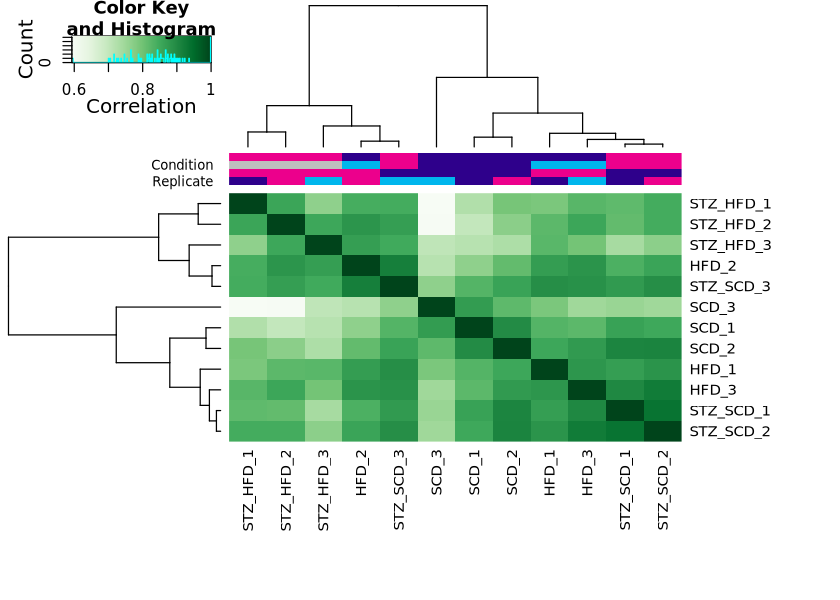

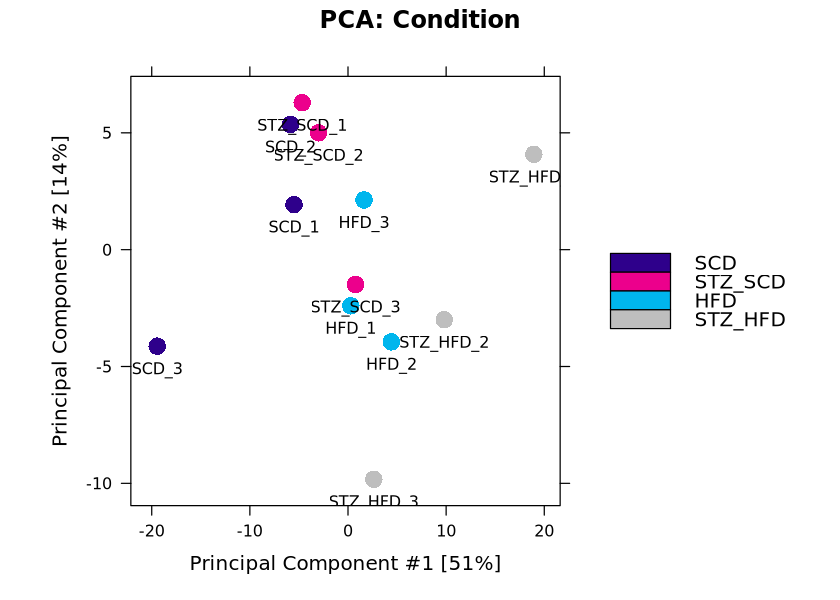

In [6]:
plot(atac)
dba.plotPCA(atac, attributes = DBA_CONDITION, label = DBA_ID)

### 1c. Normalisation

Samples have different sequencing depths, so raw counts are not comparable. Normalisation computes a **size factor** per sample. Which reads you use to compute it matters:

| method | idea | assumes |
|---|---|---|
| library size, full (`DBA_LIBSIZE_FULL`, DiffBind's default) | total fragments in the BAM | same fraction of background in every sample |
| library size, reads in peaks (`DBA_LIBSIZE_PEAKREADS`) | total fragments in consensus peaks | same total accessibility in every sample |
| RLE (`DBA_NORM_RLE`, DESeq2's method) | median ratio to a pseudo-reference over all peaks | most peaks don't change |
| background bins (`background = TRUE`) | counts in large (15 kb) bins across the genome | background is the same in every sample |

If FRiP differs between samples (part 2), the first two give different answers. Let's compare the size factors:

In [7]:
size_factors_of <- function(dba_obj, ...) {  # normalise, then read back the size factors
    dba.normalize(dba.normalize(dba_obj, ...), bRetrieve = TRUE)$norm.factors
}
# one size factor per sample for each method; a sample with a higher factor gets its counts divided by more
size_factors <- data.frame(
    sample = samples$sample,
    FRiP = dba.show(atac)$FRiP,
    libsize_full = round(size_factors_of(atac, normalize = DBA_NORM_LIB, library = DBA_LIBSIZE_FULL), 2),
    RLE_in_peaks = round(size_factors_of(atac, normalize = DBA_NORM_RLE, library = DBA_LIBSIZE_PEAKREADS), 2)
)
size_factors

,sample,FRiP,libsize_full,RLE_in_peaks
,<chr>,<dbl>,<dbl>,<dbl>
SCD_1,SCD_1,0.07,0.99,1.03
SCD_2,SCD_2,0.08,0.89,1.03
SCD_3,SCD_3,0.10,0.99,1.48
STZ_SCD_1,STZ_SCD_1,0.08,0.96,1.15
STZ_SCD_2,STZ_SCD_2,0.08,1.13,1.30
STZ_SCD_3,STZ_SCD_3,0.07,1.16,1.21
HFD_1,HFD_1,0.06,1.19,1.13
HFD_2,HFD_2,0.06,1.12,1.07
HFD_3,HFD_3,0.07,1.02,1.02


We start with DiffBind's default (library size), and compare with RLE below.

### 1d. Contrast and analysis

We compare **STZ + HFD** against **standard chow (SCD)**. The other two groups are not part of this contrast, but they still help to estimate the dispersion. By default `dba.analyze` runs only DESeq2; with `method = DBA_ALL_METHODS` it runs both DESeq2 and edgeR.

In [8]:
atac <- dba.normalize(atac)  # default: library size
# contrast = c(column of the sample sheet, numerator group, denominator group)
atac <- dba.contrast(atac, contrast = c("Condition", "STZ_HFD", "SCD"))
atac <- dba.analyze(atac, method = DBA_ALL_METHODS)
dba.show(atac, bContrasts = TRUE)

Computing results names...

Applying Blacklist/Greylists...

Genome detected: Mmusculus.UCSC.mm10

Applying blacklist...

Removed: 0 of 658 intervals.

No intervals removed.

Normalize edgeR with defaults...

Analyzing...



,Factor,Group,Samples,Group2,Samples2,DB.edgeR,DB.DESeq2
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Condition,STZ_HFD,3,SCD,3,264,261


The `DB.DESeq2` and `DB.edgeR` columns give the number of differentially accessible sites at FDR < 0.05. How much do the two methods agree?

Generating report-based DBA object...



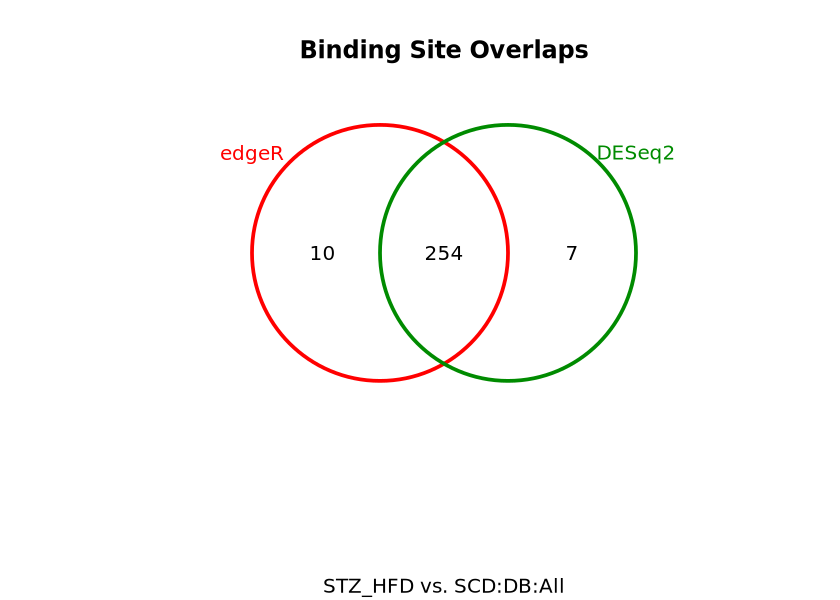

In [9]:
dba.plotVenn(atac, contrast = 1, method = DBA_ALL_METHODS)

`dba.report` returns the significant sites as a `GRanges` object, with the mean normalised accessibility (`Conc`, log2) per group, the log2 fold change (`Fold`, positive = more accessible in STZ_HFD), the p-value and the FDR:

In [10]:
# th: FDR threshold of the report
db_diffbind <- dba.report(atac, method = DBA_DESEQ2, th = 0.05)
cat(sum(db_diffbind$Fold > 0), "sites more accessible in STZ_HFD,", sum(db_diffbind$Fold < 0), "in SCD\n")
head(db_diffbind)

9 sites more accessible in STZ_HFD, 252 in SCD


GRanges object with 6 ranges and 6 metadata columns:
      seqnames            ranges strand |      Conc Conc_STZ_HFD  Conc_SCD
         <Rle>         <IRanges>  <Rle> | <numeric>    <numeric> <numeric>
  127    chr19   7039945-7040445      * |   6.63698      5.62253   7.22673
  112    chr19   6363302-6363802      * |   6.96112      5.97148   7.54261
   43    chr19   4510053-4510553      * |   6.56605      5.75266   7.08303
  172    chr19 10101548-10102048      * |   6.01283      4.95163   6.61763
    5    chr19   3575583-3576083      * |   6.22211      5.38341   6.74904
   26    chr19   4097041-4097541      * |   6.39904      5.41573   6.97840
           Fold     p-value         FDR
      <numeric>   <numeric>   <numeric>
  127  -1.51754 1.27269e-14 8.37429e-12
  112  -1.43771 4.48824e-13 1.47663e-10
   43  -1.21880 7.03416e-10 1.42053e-07
  172  -1.45996 8.63542e-10 1.42053e-07
    5  -1.25555 4.11720e-09 5.41823e-07
   26  -1.36829 8.45967e-09 9.27743e-07
  -------
  seqinfo: 1 sequ

DiffBind has plotting functions for the result. An **MA plot** shows the fold change against the mean accessibility of each site (significant ones in red); a **volcano plot** shows the fold change against significance; the **box plot** shows the accessibility of the significant sites per group.

Warning message in (function (z, notch = FALSE, width = NULL, varwidth = FALSE, :
“some notches went outside hinges ('box'): maybe set notch=FALSE”


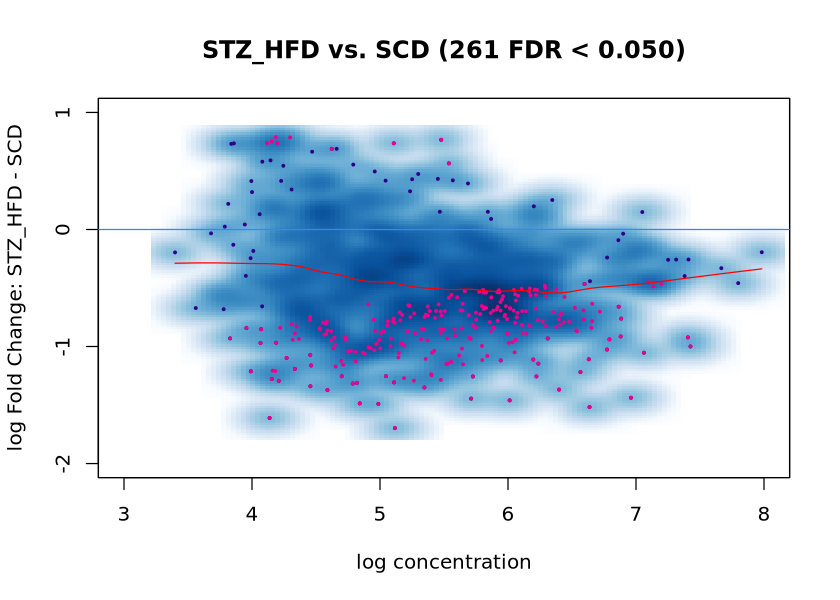

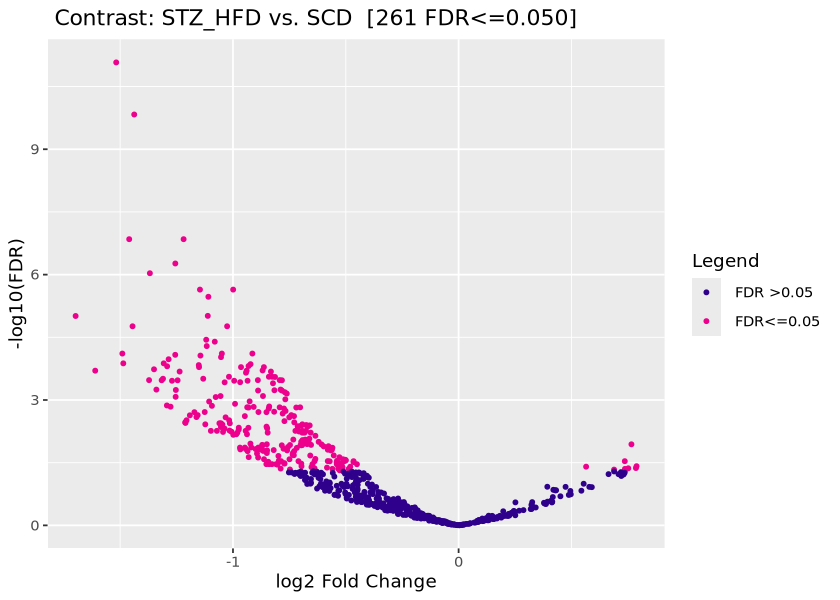

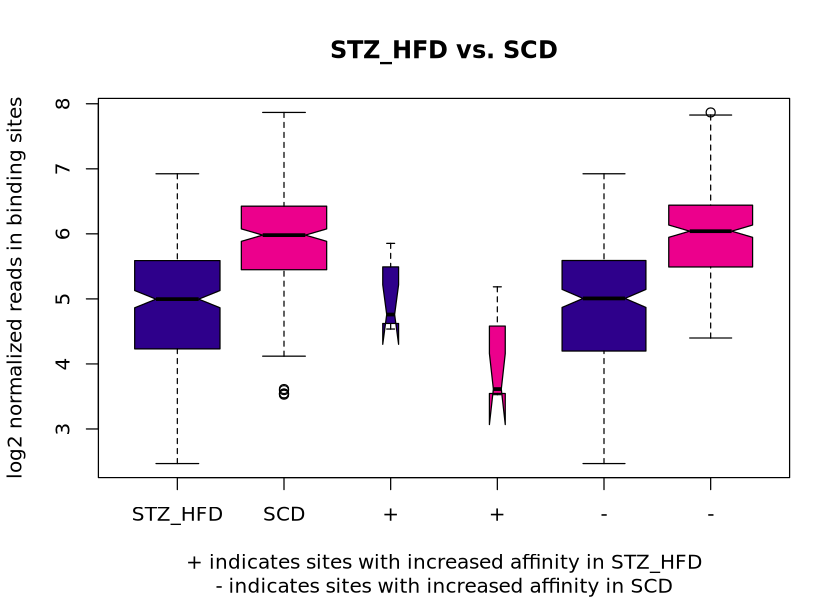

In [11]:
dba.plotMA(atac, method = DBA_DESEQ2)
dba.plotVolcano(atac, method = DBA_DESEQ2)
dba.plotBox(atac, method = DBA_DESEQ2)

Almost all significant sites are more accessible in SCD, and the cloud of the MA plot sits below 0. Is the treatment really closing chromatin everywhere, or is this the normalisation? Let's repeat the analysis with RLE normalisation on the reads in peaks (`normalize = DBA_NORM_RLE, library = DBA_LIBSIZE_PEAKREADS`) and compare the number of sites in each direction:

In [12]:
# same analysis, only the normalisation changes: RLE (DESeq2's method) computed on the reads in peaks
atac_rle <- dba.normalize(atac, normalize = DBA_NORM_RLE, library = DBA_LIBSIZE_PEAKREADS)
atac_rle <- dba.analyze(atac_rle, method = DBA_DESEQ2)
db_rle <- dba.report(atac_rle, method = DBA_DESEQ2, th = 0.05)
data.frame(normalisation = c("library size (full)", "RLE (reads in peaks)"),
           up_in_STZ_HFD = c(sum(db_diffbind$Fold > 0), sum(db_rle$Fold > 0)),
           up_in_SCD     = c(sum(db_diffbind$Fold < 0), sum(db_rle$Fold < 0)))

Analyzing...

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates



normalisation,up_in_STZ_HFD,up_in_SCD
<chr>,<int>,<int>
library size (full),9,252
RLE (reads in peaks),56,41


Library-size normalisation assumes the same fraction of background reads in every sample. If one group has a higher FRiP (better signal-to-noise, or more open chromatin overall), all of its peaks look higher, and many sites become "more accessible" in that group. RLE on reads in peaks assumes instead that most peaks don't change, and centres the fold changes around zero. Neither is always right: check the MA plot (is the cloud of non-significant sites centred on 0?) and think about the biology (could the treatment really open or close chromatin globally?).

That is exactly what happens here. The SCD libraries have a higher FRiP (0.07-0.10) than the STZ_HFD libraries (0.05-0.06; see the size factors above, STZ_HFD_1 is the weakest library of the experiment). With library-size normalisation about 250 of the ~260 DARs are "up in SCD" and the MA plot cloud sits below 0: mostly a difference in library quality. With RLE the DARs are balanced (about 55 up and 40 down) and the cloud is centred.

In the rest of the notebook we use RLE (DESeq2's default).

## Step 2: DESeq2 on the count matrix

DiffBind is convenient, but it hides the steps. Now we use DESeq2 directly on the count matrix we built in [part 2](part_2_consensus_peaks_macs_diff.ipynb) (fixed-width consensus peaks, counted with featureCounts). This is the same workflow as for RNA-seq, with peaks instead of genes. Step 3 of the [bulk RNA-seq practical, part 2](../bulk-rna-seq/part_2_differential_expression.ipynb) explains how DESeq2 models the counts (negative binomial distribution, size factors, dispersion, shrinkage); here we focus on what is different for ATAC-seq.

In [13]:
counts <- as.matrix(read.delim(file.path(nb02, "counts_matrix.tsv"), row.names = 1, check.names = FALSE))
# same sample order as the sample sheet: DESeq2 matches columns of the counts to rows of colData by position
counts <- counts[, samples$sample]
dim(counts)
head(counts)
colSums(counts)

[1] 715  12

,SCD_1,SCD_2,SCD_3,STZ_SCD_1,STZ_SCD_2,STZ_SCD_3,HFD_1,HFD_2,HFD_3,STZ_HFD_1,STZ_HFD_2,STZ_HFD_3
peak1,33,35,54,39,28,32,25,19,24,19,22,44
peak2,68,65,79,64,92,61,49,80,61,36,48,42
peak5,43,39,63,34,43,23,28,21,39,9,21,23
peak7,64,76,76,79,68,62,60,63,60,32,43,56
peak8,81,70,103,92,106,85,57,68,70,26,35,34
peak11,42,23,50,32,44,28,30,18,35,7,23,12


SCD_1     SCD_2     SCD_3 STZ_SCD_1 STZ_SCD_2 STZ_SCD_3     HFD_1     HFD_2 
    32119     32764     47189     36670     41872     38840     35445     34667 
    HFD_3 STZ_HFD_1 STZ_HFD_2 STZ_HFD_3 
    32588     14314     24804     30444

### 2a. A one-factor design

The simplest design treats the four groups as one factor, `~ group`. DESeq2 then estimates size factors (RLE), dispersions, and one coefficient per group relative to the reference (SCD).

In [14]:
dds <- DESeqDataSetFromMatrix(countData = counts, colData = samples, design = ~ group)
# DESeq() runs all steps: size factors, dispersions, model fit and Wald tests
dds <- DESeq(dds)
sizeFactors(dds)
resultsNames(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



SCD_1     SCD_2     SCD_3 STZ_SCD_1 STZ_SCD_2 STZ_SCD_3     HFD_1     HFD_2 
1.0086156 1.0222569 1.4616391 1.1489744 1.2979642 1.2109072 1.1398250 1.0798372 
    HFD_3 STZ_HFD_1 STZ_HFD_2 STZ_HFD_3 
1.0254721 0.4431956 0.7586939 0.9637208

[1] "Intercept"            "group_STZ_SCD_vs_SCD" "group_HFD_vs_SCD"    
[4] "group_STZ_HFD_vs_SCD"

Before testing, look at the samples. The **variance-stabilising transformation** (`vst`) puts counts on a log2-like scale where the variance no longer depends on the mean, which is what PCA and distance plots need.

using ntop=500 top features by variance

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the DESeq2 package.
  Please report the issue to the authors.”


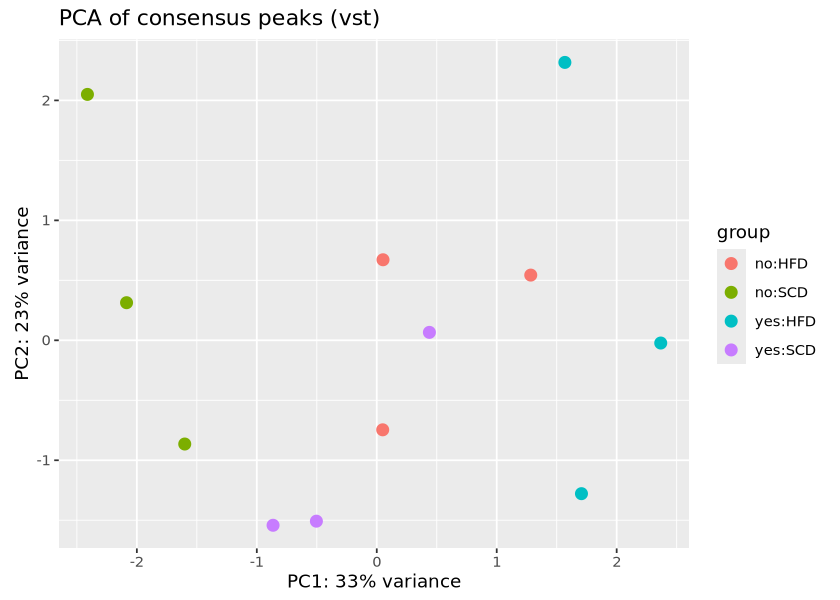

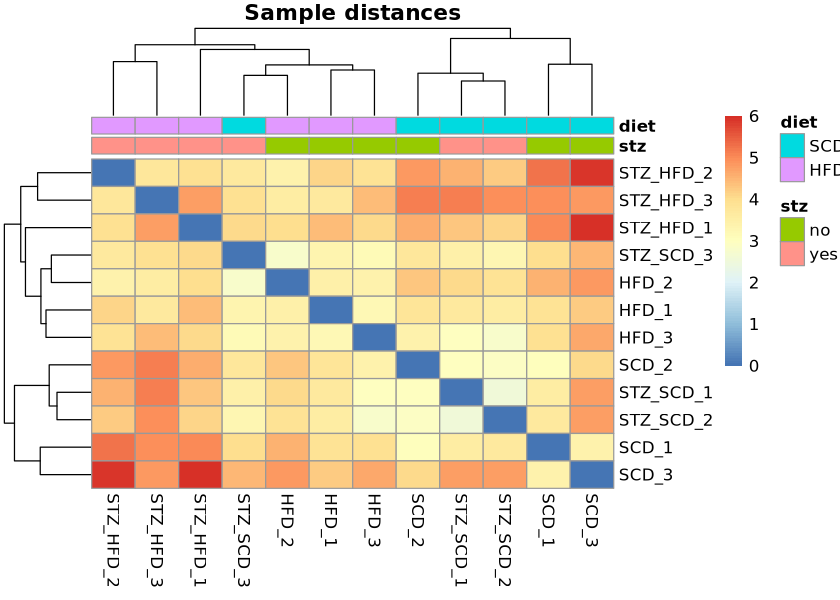

In [15]:
# vst() fits the transformation on a subset of 1000 regions; chr19 has fewer, so we use the full version
vsd <- varianceStabilizingTransformation(dds, blind = TRUE)
plotPCA(vsd, intgroup = c("stz", "diet")) + ggtitle("PCA of consensus peaks (vst)")

# Euclidean distances between samples (t(): samples as rows)
sample_dist <- as.matrix(dist(t(assay(vsd))))
pheatmap(sample_dist, annotation_col = samples[, c("stz", "diet")], main = "Sample distances")

Which factor separates the samples along the first principal component: STZ or diet? Is there an outlier?

Now the test for STZ_HFD versus SCD. `alpha = 0.05` is the FDR threshold used for the summary and for independent filtering (DESeq2 removes regions with very low counts, which can never be significant, to gain power).

In [16]:
# contrast = c(factor, numerator, denominator): log2 fold change STZ_HFD / SCD
res <- results(dds, contrast = c("group", "STZ_HFD", "SCD"), alpha = 0.05)
summary(res)
head(res[order(res$padj), ])


out of 715 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 45, 6.3%
LFC < 0 (down)     : 36, 5%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 10)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



log2 fold change (MLE): group STZ_HFD vs SCD 
Wald test p-value: group STZ HFD vs SCD 
DataFrame with 6 rows and 6 columns
         baseMean log2FoldChange     lfcSE      stat      pvalue        padj
        <numeric>      <numeric> <numeric> <numeric>   <numeric>   <numeric>
peak190   83.1244      -1.118670  0.216940  -5.15660 2.51476e-07 0.000179805
peak170  105.9637      -0.954481  0.199861  -4.77571 1.79073e-06 0.000502228
peak561   46.4727       1.355597  0.285819   4.74286 2.10725e-06 0.000502228
peak345   25.1164       1.671440  0.361383   4.62512 3.74389e-06 0.000669221
peak256   54.4270      -1.025403  0.252981  -4.05329 5.05033e-05 0.004012210
peak440   34.2655       1.368706  0.336981   4.06167 4.87235e-05 0.004012210

Fold changes of regions with few fragments are noisy: a change from 2 to 8 fragments is a log2 fold change of 2 but means little. **Shrinkage** (here with `apeglm`) pulls such uncertain fold changes towards zero, while keeping strong, well-supported ones. Use shrunken fold changes for ranking and plotting; the p-values do not change.

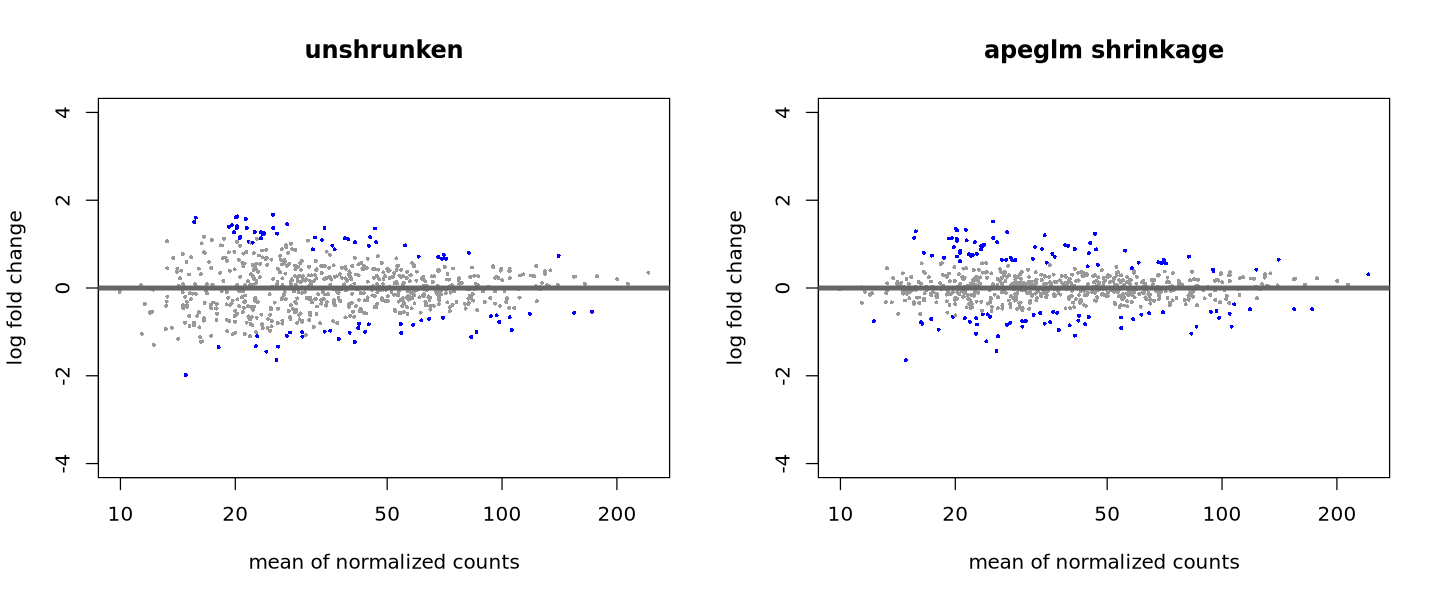

In [17]:
# apeglm shrinks one coefficient, named as in resultsNames(dds)
res_shrunk <- lfcShrink(dds, coef = "group_STZ_HFD_vs_SCD", type = "apeglm", quiet = TRUE)
# two plots side by side (wider figure, 1 row x 2 columns)
options(repr.plot.width = 12, repr.plot.height = 5)
par(mfrow = c(1, 2))
plotMA(res, ylim = c(-4, 4), main = "unshrunken")
plotMA(res_shrunk, ylim = c(-4, 4), main = "apeglm shrinkage")
par(mfrow = c(1, 1))
options(repr.plot.width = 7, repr.plot.height = 5)

A volcano plot with the shrunken fold changes, and the normalised counts of the most significant region in each sample. Always look at the counts of your top hits: do all three replicates agree?

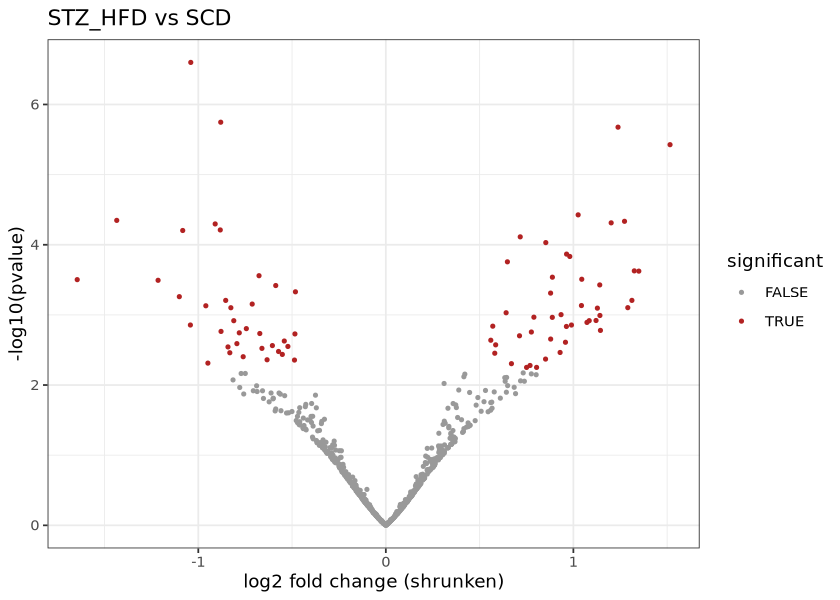

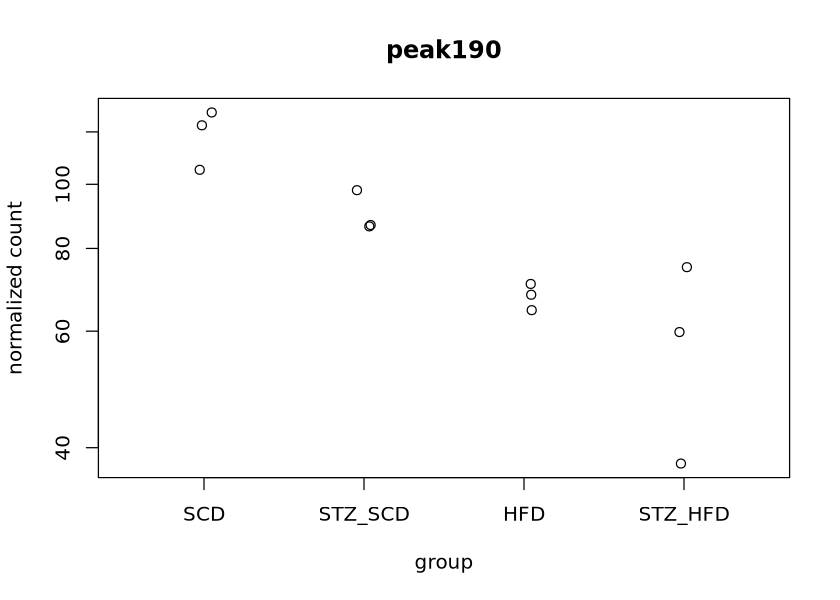

In [18]:
volcano <- as.data.frame(res_shrunk)
volcano$significant <- !is.na(volcano$padj) & volcano$padj < 0.05
ggplot(volcano, aes(log2FoldChange, -log10(pvalue), colour = significant)) +
    geom_point(size = 0.8) + scale_colour_manual(values = c("grey60", "firebrick")) +
    labs(title = "STZ_HFD vs SCD", x = "log2 fold change (shrunken)") + theme_bw()

# the region with the smallest adjusted p-value, and its normalised counts per sample
top_peak <- rownames(res)[which.min(res$padj)]
plotCounts(dds, gene = top_peak, intgroup = "group", main = top_peak)

### 2b. A factorial design: STZ × diet

The experiment is a 2 × 2 design: two factors (STZ yes/no, diet SCD/HFD), all four combinations. Instead of four unrelated groups, we can model the factors directly:

`~ stz + diet + stz:diet`

| coefficient | meaning |
|---|---|
| `stz_yes_vs_no` | effect of STZ **on standard chow** |
| `diet_HFD_vs_SCD` | effect of the high-fat diet **without STZ** |
| `stzyes.dietHFD` | **interaction**: the extra change when STZ and HFD are combined, beyond the sum of both separate effects |

The interaction answers a question the pairwise comparison cannot: do the two treatments act independently, or does the combination do something neither does alone? That is exactly the claim of the paper (STZ + HFD drives fast disease progression).

In [19]:
dds_fact <- DESeqDataSetFromMatrix(countData = counts, colData = samples, design = ~ stz + diet + stz:diet)
dds_fact <- DESeq(dds_fact)
resultsNames(dds_fact)

# name = one coefficient of resultsNames(); alpha = FDR threshold
res_interaction <- results(dds_fact, name = "stzyes.dietHFD", alpha = 0.05)
summary(res_interaction)


out of 715 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 0, 0%
LFC < 0 (down)     : 0, 0%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 10)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"       "stz_yes_vs_no"   "diet_HFD_vs_SCD" "stzyes.dietHFD"

With this design, the STZ_HFD vs SCD comparison is the **sum** of the three coefficients. It gives the same fold changes as the one-factor design (the p-values can differ slightly because the dispersions are estimated with another model):

In [20]:
# contrast = list(c(...)): add up these coefficients
res_sum <- results(dds_fact, contrast = list(c("stz_yes_vs_no", "diet_HFD_vs_SCD", "stzyes.dietHFD")), alpha = 0.05)
cat("correlation of log2 fold changes with the one-factor design:",
    round(cor(res_sum$log2FoldChange, res$log2FoldChange, use = "complete.obs"), 4), "\n")

correlation of log2 fold changes with the one-factor design: 1 


The interaction gives no significant region on chr19 (see the summary above), although STZ_HFD vs SCD gives about 80. An interaction is a *difference of differences*, which is estimated with roughly twice the variance of a simple comparison, so it needs more replicates (or more regions, genome-wide) to be detected. "Not significant" does not mean "no interaction". Exercise 1 at the end of this notebook looks at the effects of STZ and diet on their own.

Let's keep the STZ_HFD vs SCD DARs of the one-factor design as GRanges, with the coordinates of the consensus peaks:

In [22]:
consensus <- read.delim(file.path(nb02, "consensus_peaks.bed"), header = FALSE, col.names = c("chr", "start", "end", "name"))
# BED starts are 0-based, GRanges are 1-based: add 1
consensus_gr <- GRanges(consensus$chr, IRanges(consensus$start + 1, consensus$end), name = consensus$name)
names(consensus_gr) <- consensus$name

# significant regions (padj < 0.05; NA = removed by independent filtering), with their shrunken fold change
res_df <- as.data.frame(res_shrunk)
sig <- rownames(res_df)[!is.na(res_df$padj) & res_df$padj < 0.05]
db_deseq2 <- consensus_gr[sig]
db_deseq2$log2FoldChange <- res_df[sig, "log2FoldChange"]
db_deseq2$padj <- res_df[sig, "padj"]
db_deseq2

GRanges object with 81 ranges and 3 metadata columns:
           seqnames            ranges strand |        name log2FoldChange
              <Rle>         <IRanges>  <Rle> | <character>      <numeric>
     peak8    chr19   3575758-3576257      * |       peak8      -0.572057
    peak23    chr19   3833100-3833599      * |      peak23      -0.878757
    peak43    chr19   4097025-4097524      * |      peak43      -0.882797
    peak70    chr19   4510079-4510578      * |      peak70      -0.676177
    peak72    chr19   4557719-4558218      * |      peak72      -1.645643
       ...      ...               ...    ... .         ...            ...
  peak1139    chr19 57197223-57197722      * |    peak1139      -0.743780
  peak1162    chr19 58395700-58396199      * |    peak1162      -0.831910
  peak1179    chr19 59407999-59408498      * |    peak1179      -1.434868
  peak1184    chr19 60144315-60144814      * |    peak1184       0.750533
  peak1206    chr19 61084427-61084926      * |    peak1206

## Step 3: Comparing the methods

We now have DARs for STZ_HFD vs SCD from three approaches:

- **DiffBind** (DESeq2 inside, DiffBind's own consensus and library-size normalisation);
- **DESeq2** on our fixed-width consensus peaks (RLE normalisation);
- **MACS3 `bdgdiff`** on pooled replicates ([part 2](part_2_consensus_peaks_macs_diff.ipynb)).

Their regions have different boundaries, so we compare them by **overlap**: a region "agrees" if it overlaps a region of another method.

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


DiffBind   DESeq2  bdgdiff 
     261       81      552

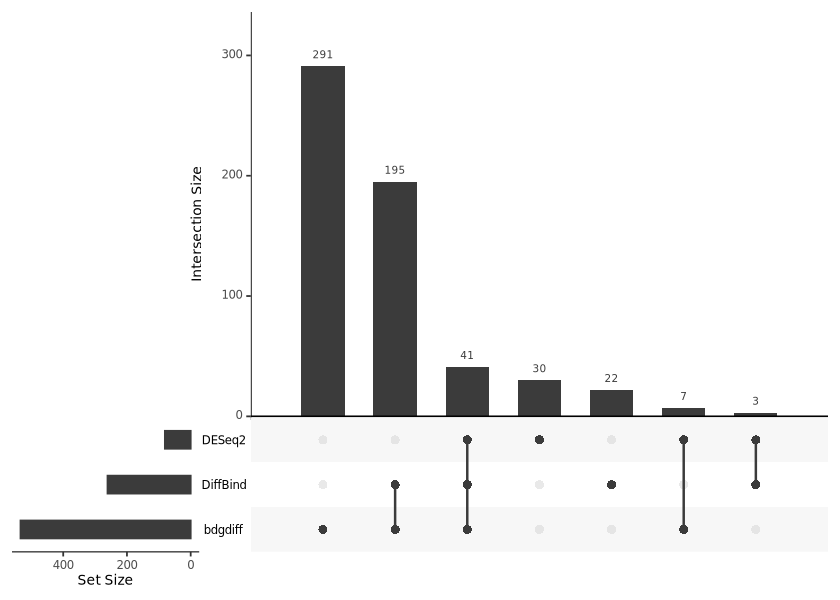

In [23]:
read_bdgdiff <- function(f) {  # bdgdiff BED (with a header line) to GRanges (1-based start)
    d <- read.delim(f, header = FALSE, skip = 1)
    GRanges(d$V1, IRanges(d$V2 + 1, d$V3))
}
db_bdgdiff <- c(read_bdgdiff(file.path(nb02, "bdgdiff", "STZ_HFD_vs_SCD_c3.0_cond1.bed")),
                read_bdgdiff(file.path(nb02, "bdgdiff", "STZ_HFD_vs_SCD_c3.0_cond2.bed")))

dar_sets <- list(DiffBind = db_diffbind, DESeq2 = db_deseq2, bdgdiff = db_bdgdiff)
sapply(dar_sets, length)

# all DAR regions together, merged; then record which method found each merged region
all_dars <- reduce(unlist(GRangesList(lapply(dar_sets, granges))))
membership <- sapply(dar_sets, function(gr) as.integer(overlapsAny(all_dars, gr)))
upset(as.data.frame(membership), order.by = "freq")

**Question**: DiffBind and our DESeq2 analysis both use DESeq2 for the test. Why don't they find exactly the same regions? And why does `bdgdiff` differ more? (Hint: list everything that happens *before* the test in each approach.)

## Step 4: Annotating DARs to genes

Which genes are near the DARs? [ChIPseeker](https://bioconductor.org/packages/ChIPseeker) assigns each region to the nearest TSS and describes its genomic context (promoter, intron, distal intergenic, ...), using the mm10 gene annotation (`TxDb.Mmusculus.UCSC.mm10.knownGene`) and gene symbols from `org.Mm.eg.db`.

'select()' returned 1:1 mapping between keys and columns

'select()' returned 1:1 mapping between keys and columns



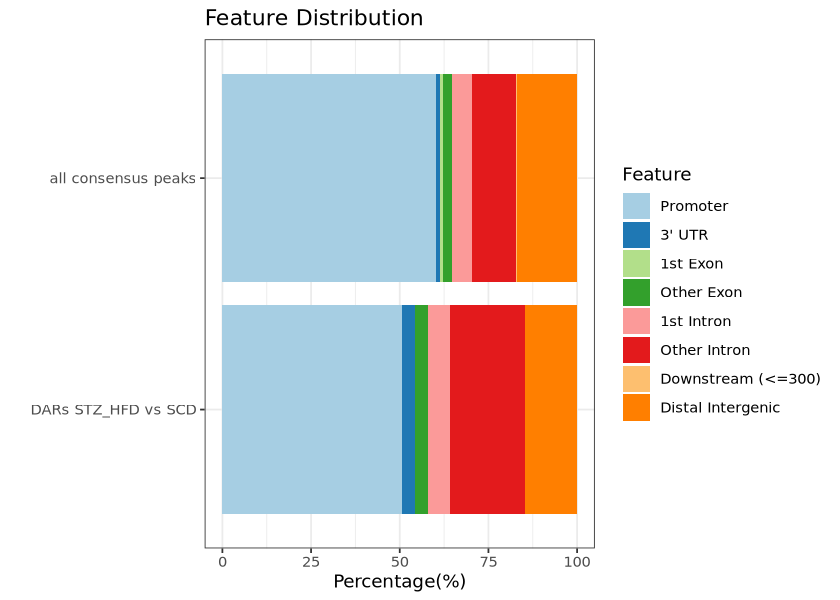

In [24]:
txdb <- TxDb.Mmusculus.UCSC.mm10.knownGene
# tssRegion: what counts as "promoter" (here ±1 kb around the TSS); annoDb adds gene symbols
annotate <- function(gr) annotatePeak(gr, TxDb = txdb, annoDb = "org.Mm.eg.db", tssRegion = c(-1000, 1000), verbose = FALSE)

anno_dars <- annotate(db_deseq2)
anno_all  <- annotate(consensus_gr)
plotAnnoBar(list("all consensus peaks" = anno_all, "DARs STZ_HFD vs SCD" = anno_dars))

Are DARs more often at promoters than peaks in general, or more often distal (enhancers)? Now the genes nearest to the strongest DARs:

In [25]:
dar_table <- as.data.frame(anno_dars)
# sort by adjusted p-value and keep the most useful columns
dar_table <- dar_table[order(dar_table$padj), c("seqnames", "start", "end", "log2FoldChange", "padj",
                                                "annotation", "distanceToTSS", "SYMBOL")]
# "Intron (uc008..., intron 2 of 5)" -> "Intron"
dar_table$annotation <- sub(" \\(.*", "", dar_table$annotation)
head(dar_table, 20)

,seqnames,start,end,log2FoldChange,padj,annotation,distanceToTSS,SYMBOL
,<fct>,<int>,<int>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
15,chr19,7040020,7040519,-1.0401362,0.0001798051,Promoter,-53,Stip1
12,chr19,6363245,6363744,-0.8803986,0.0005022282,Promoter,0,Sf1
46,chr19,26747953,26748452,1.2381131,0.0005022282,Promoter,0,Smarca2
30,chr19,14635286,14635785,1.5154584,0.0006692208,Distal Intergenic,-37235,Tle4
21,chr19,10101488,10101987,-0.9099664,0.0040122098,Promoter,0,Fads2
38,chr19,21127450,21127949,1.2015958,0.0040122098,Intron,22740,4930554I06Rik
41,chr19,21912930,21913429,1.0255175,0.0040122098,Distal Intergenic,134542,Cemip2
42,chr19,21913616,21914115,1.2727159,0.0040122098,Distal Intergenic,135228,Cemip2
79,chr19,59407999,59408498,-1.4348679,0.0040122098,Distal Intergenic,-49874,Emx2


### Back to the promoters of part 1

In [part 1](part_1_reads_to_peaks.ipynb) we looked at the promoters of *Scd1*, *Cpt1a*, *Fads1*, *Fads2*, *Rbp4* and *Pten* in one mouse per group. Let's see which of these genes have a DAR nearby (any annotation), and the DESeq2 result of all consensus peaks near them:

In [26]:
genes <- c("Scd1", "Cpt1a", "Fads1", "Fads2", "Rbp4", "Pten")
# significant DARs annotated to one of these genes
dar_table[dar_table$SYMBOL %in% genes, ]

# all consensus peaks near these genes, significant or not: add the DESeq2 result by region name
all_table <- as.data.frame(anno_all)
all_table$log2FoldChange <- res_df[all_table$name, "log2FoldChange"]
all_table$padj <- res_df[all_table$name, "padj"]
all_table[all_table$SYMBOL %in% genes, c("name", "SYMBOL", "distanceToTSS", "log2FoldChange", "padj")]

,seqnames,start,end,log2FoldChange,padj,annotation,distanceToTSS,SYMBOL
,<fct>,<int>,<int>,<dbl>,<dbl>,<chr>,<dbl>,<chr>
21,chr19,10101488,10101987,-0.9099664,0.00401221,Promoter,0,Fads2
67,chr19,44407278,44407777,-1.1011671,0.01403555,Promoter,0,Scd1


,name,SYMBOL,distanceToTSS,log2FoldChange,padj
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
2,peak2,Cpt1a,0,-0.01214907,0.96316806
3,peak5,Cpt1a,-179,-0.50042199,0.12186186
182,peak254,Fads2,0,-0.31573222,0.25939519
183,peak255,Fads2,518,-0.12275852,0.63652995
184,peak256,Fads2,0,-0.90996644,0.00401221
185,peak258,Fads2,-25140,-0.10084882,0.53248656
186,peak259,Fads1,-33362,-0.32295463,0.25451737
187,peak260,Fads1,0,-0.28694675,0.24328365
413,peak686,Pten,-956,-0.09197503,0.71027454


The promoters of *Scd1* and *Fads2* (both fatty-acid desaturases of lipogenesis) are significantly less accessible in STZ_HFD; *Fads1*, *Rbp4* and the region just upstream of the *Cpt1a* TSS show smaller, non-significant decreases, while the *Cpt1a* TSS peak and the *Pten* promoter do not change. In part 1 the one-mouse comparison (SCD_3 vs STZ_HFD_3) showed **all** six promoters as less accessible, *Pten* included (by 30%), and *Scd1* and *Fads2* by about a factor of three. With replicates and a suitable normalisation, the direction for *Scd1* and *Fads2* holds, the size of the change is smaller (about 2-fold), and the drop of *Pten* is not a treatment effect: it came from the comparison of two single mice (the lower signal-to-noise of the STZ_HFD_3 library, or normal mouse-to-mouse variation).

Remember that accessibility is not expression: a less accessible promoter is consistent with, but does not prove, lower transcription.

## Step 5: Saving the results

We write the DARs as BED files (for IGV, or for motif enrichment and other downstream analyses) and the full result table.

In [27]:
write_bed <- function(gr, file) {
    write.table(data.frame(seqnames(gr), start(gr) - 1, end(gr), names(gr)), file,
                sep = "\t", quote = FALSE, row.names = FALSE, col.names = FALSE)
}
write_bed(db_deseq2[db_deseq2$log2FoldChange > 0], "DARs_up_in_STZ_HFD.bed")
write_bed(db_deseq2[db_deseq2$log2FoldChange < 0], "DARs_up_in_SCD.bed")
write.table(dar_table, "DARs_STZ_HFD_vs_SCD_annotated.tsv", sep = "\t", quote = FALSE, row.names = FALSE)
list.files()

[1] "DARs_STZ_HFD_vs_SCD_annotated.tsv" "DARs_up_in_SCD.bed"               
[3] "DARs_up_in_STZ_HFD.bed"

## Comparison with the paper

Jeong et al. analysed the same 12 libraries genome-wide with DiffBind (version 3.4) and DESeq2 (adjusted p < 0.05). They report that the chromatin landscape of STZ + HFD mice differs from the other groups and is dominated by **chromatin closing**, with closed regions near genes of the DNA damage response and the response to misfolded proteins (Supplementary Fig. 5g-j of the paper).

| | this practical | paper |
|---|---|---|
| data | chr19 only | genome-wide |
| trimming | fastp | Trim Galore |
| alignment | bowtie2 `--very-sensitive -X 2000` | bowtie2 `--very-sensitive` |
| duplicates, chrM, blacklist | removed (Picard, samtools, bedtools) | removed (Picard, samtools, bedtools) |
| peaks | MACS3, paired-end mode | MACS2 |
| differential test | DiffBind + DESeq2; DESeq2 on our own consensus | DiffBind + DESeq2 |
| STZ_HFD vs SCD, library-size normalisation | ~250 of ~260 DARs less accessible in STZ_HFD | mostly closing |
| STZ_HFD vs SCD, RLE normalisation | balanced: ~55 more and ~40 less accessible (DiffBind); ~45 and ~35 (DESeq2) | not reported |

With DiffBind's default library-size normalisation we see the same picture as the paper: almost all DARs are less accessible in STZ + HFD. But the STZ_HFD libraries also have a lower FRiP, and with a normalisation that does not depend on the fraction of reads in peaks (RLE) the DARs are balanced. The paper does not state which normalisation it used, so we cannot say how much of its "closing" is biology and how much is library quality; our analysis shows that the question matters. We also cannot test the gene ontology result with chr19 alone.

Our numbers are different from the paper's anyway, because we only look at chr19 and use a different pipeline (fastp instead of Trim Galore, MACS3 in paired-end mode instead of MACS2, our own consensus peaks).

## Conclusion

1. **How good are the libraries?** Alignment, duplication and mitochondrial reads are fine, but TSS enrichment and FRiP (0.04-0.12) are modest and differ between mice, and the STZ_HFD libraries tend to be weaker. Library quality shows up everywhere downstream: in the number of peaks per sample, in MACS3 `bdgdiff` (two control mice already give ~180 "differential" regions) and in the normalisation.
2. **Which regions change?** With replicates and RLE normalisation, about 80 regions on chr19 change accessibility between STZ + HFD and control mice, in both directions. With library-size normalisation, almost all of them seem to close in STZ + HFD, which is at least partly a difference in library quality.
3. **Which genes are nearby?** The promoters of the lipogenic desaturases *Scd1* and *Fads2* are less accessible in STZ + HFD livers (about 2-fold), while the control gene *Pten* does not change. *Scd1* is induced by insulin, so this fits with insulin deficiency after streptozotocin, but accessibility is not expression: RNA-seq of the same livers would be needed to confirm it.

What to remember beyond this dataset:

- **Replicates** make differential accessibility testable: DiffBind and DESeq2 estimate the mouse-to-mouse variation and control the false discovery rate; MACS3 `bdgdiff` cannot.
- **Choices before the test matter**: consensus peaks, counting and especially normalisation change the list of DARs. Check the MA plot and report which choices you made.
- **Designs** can answer more than pairwise questions: the factorial model separates the effects of STZ and diet and their interaction.

In the next practical we move to [**single-cell ATAC-seq**](../single-cell-atac-seq/index.md), where accessibility is measured in thousands of individual cells.

## Exercises

1. Which treatment changes more regions on its own, STZ or the high-fat diet? Use `results()` with the two main-effect coefficients of `dds_fact` (`stz_yes_vs_no` and `diet_HFD_vs_SCD`, see `resultsNames(dds_fact)`) and count the regions with FDR < 0.05 in each direction. Compare with the interaction and with STZ_HFD vs SCD.
2. Normalise the DiffBind object with background bins (`dba.normalize(atac, background = TRUE)`) and repeat the analysis. Is the result closer to library-size or to RLE normalisation? Why?
3. Annotate the DARs found by DiffBind with library-size normalisation (`db_diffbind`) with ChIPseeker. Are they near different genes, or in different genomic contexts, than the DESeq2 DARs?
4. Compare the other groups with SCD (`contrast = c("group", "HFD", "SCD")` and `c("group", "STZ_SCD", "SCD")`). Which treatment is closest to the controls? Does that match the PCA?